# Homework 5.2 - Steps 7-8

## Generate New Token Trajectories and Test Lorenz Geometry

This notebook uses the validation-selected Markov context model from Steps 5-6 to generate new token trajectories.

The generated tokens are mapped back to approximate continuous states using the centers of their phase-space boxes.

We then test two questions:

1. Do generated trajectories remain near the region occupied by the Lorenz attractor?
2. Do they reproduce the characteristic switching between the two Lorenz lobes?

The generated sequences are stochastic samples from the learned discrete model. They are not numerical integrations of the Lorenz ODE.

## Generation protocol

For each held-out test book, the first $$m$$ tokens are used only as the initial seed context.

From that point onward,

$$
a_{n+1}
\sim
P(
\cdot
\mid
a_{n-m+1},\ldots,a_n
).
$$

If the generated history is unseen, the same backoff rule from Steps 5-6 is used.

Ten generated trajectories are produced from each of the 10 test seeds, giving 100 generated sequences.

The future test tokens are not used during generation.

In [1]:
from pathlib import Path
from collections import Counter, defaultdict
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree

cwd = Path.cwd()
PROJECT_ROOT = cwd.parent if cwd.name.lower() == "codes" else cwd

DATA_DIR = PROJECT_ROOT / "data" / "hw5_2"
RESULT_DIR = PROJECT_ROOT / "result images" / "hw5_2"

TOKEN_DIR = DATA_DIR / "token_books"
TRAJECTORY_DIR = DATA_DIR / "trajectories"
GENERATED_DIR = DATA_DIR / "generated_sequences"

GENERATED_DIR.mkdir(parents=True, exist_ok=True)

config = json.loads(
    (
        DATA_DIR
        / "baseline_configuration.json"
    ).read_text(
        encoding="utf-8"
    )
)

selection = json.loads(
    (
        DATA_DIR
        / "task5_6_selected_markov_model.json"
    ).read_text(
        encoding="utf-8"
    )
)

SELECTED_M = int(
    selection[
        "selected_context_length_m"
    ]
)

VOCAB_SIZE = int(
    config[
        "possible_vocabulary_size"
    ]
)

DT = float(
    config[
        "sampling_interval_dt"
    ]
)

GENERATION_SEED = 63878
GENERATIONS_PER_TEST_SEED = 10

rng = np.random.default_rng(
    GENERATION_SEED
)

print("Selected context length m:", SELECTED_M)
print("Vocabulary size:", VOCAB_SIZE)

Selected context length m: 3
Vocabulary size: 1728


In [2]:
def load_token_books(split_name):
    paths = sorted(
        (TOKEN_DIR / split_name)
        .glob("book_*.csv")
    )

    books = []

    for path in paths:
        frame = pd.read_csv(path)

        books.append(
            frame["token"].to_numpy(
                dtype=np.int64
            )
        )

    return books


def load_continuous_books(split_name):
    paths = sorted(
        (TRAJECTORY_DIR / split_name)
        .glob("book_*.npz")
    )

    books = []

    for path in paths:
        data = np.load(path)
        books.append(data["states"])

    return books


train_books = load_token_books("train")
validation_books = load_token_books("validation")
test_books = load_token_books("test")

train_continuous = load_continuous_books("train")
validation_continuous = load_continuous_books("validation")
test_continuous = load_continuous_books("test")

print("Training books:", len(train_books))
print("Validation books:", len(validation_books))
print("Test books:", len(test_books))

Training books: 40
Validation books: 10
Test books: 10


## Refit the selected training model

The model is refit only from the training token books using the already-selected context length.

In [3]:
def fit_ngram_model(books, max_order):
    models = {
        order: defaultdict(Counter)
        for order in range(
            1,
            max_order + 1,
        )
    }

    unigram_counts = Counter()

    for sequence in books:
        unigram_counts.update(
            sequence.tolist()
        )

        for order in range(
            1,
            max_order + 1,
        ):
            for i in range(
                order,
                len(sequence),
            ):
                history = tuple(
                    int(x)
                    for x in sequence[
                        i-order:i
                    ]
                )

                next_token = int(
                    sequence[i]
                )

                models[order][history][
                    next_token
                ] += 1

    return models, unigram_counts


models, unigram_counts = fit_ngram_model(
    train_books,
    SELECTED_M,
)


def backoff_counter(history):
    history = tuple(
        int(x)
        for x in history
    )

    for order in range(
        min(
            SELECTED_M,
            len(history),
        ),
        0,
        -1,
    ):
        key = history[-order:]

        if key in models[order]:
            return models[order][key], order

    return unigram_counts, 0


def sample_next_token(history, rng):
    counter, used_order = (
        backoff_counter(history)
    )

    tokens = np.array(
        list(counter.keys()),
        dtype=np.int64,
    )

    counts = np.array(
        list(counter.values()),
        dtype=float,
    )

    probabilities = counts / counts.sum()

    token = int(
        rng.choice(
            tokens,
            p=probabilities,
        )
    )

    return token, used_order

## Generate 100 synthetic token trajectories

In [4]:
generated_records = []
generated_sequences = []

for test_book_index, true_sequence in enumerate(
    test_books
):
    seed_context = true_sequence[
        :SELECTED_M
    ].tolist()

    target_length = len(
        true_sequence
    )

    for replicate in range(
        GENERATIONS_PER_TEST_SEED
    ):
        generated = list(
            seed_context
        )

        backoff_counts = Counter()

        while len(generated) < target_length:
            next_token, used_order = (
                sample_next_token(
                    generated,
                    rng,
                )
            )

            generated.append(
                next_token
            )

            backoff_counts[
                used_order
            ] += 1

        generated = np.asarray(
            generated,
            dtype=np.int64,
        )

        generated_sequences.append(
            generated
        )

        output_path = (
            GENERATED_DIR
            / (
                f"seed_{test_book_index:02d}"
                f"_rep_{replicate:02d}.csv"
            )
        )

        pd.DataFrame({
            "sample_index": np.arange(
                len(generated)
            ),
            "token": generated,
        }).to_csv(
            output_path,
            index=False,
        )

        generated_records.append({
            "test_seed_book": (
                test_book_index
            ),
            "replicate": replicate,
            "length": len(generated),
            "full_context_steps": int(
                backoff_counts.get(
                    SELECTED_M,
                    0,
                )
            ),
            "shorter_backoff_steps": int(
                sum(
                    count
                    for order, count
                    in backoff_counts.items()
                    if order < SELECTED_M
                )
            ),
            "file": str(
                output_path.relative_to(
                    PROJECT_ROOT
                )
            ),
        })


generated_manifest = pd.DataFrame(
    generated_records
)

generated_manifest_path = (
    DATA_DIR
    / "task7_generated_sequence_manifest.csv"
)

generated_manifest.to_csv(
    generated_manifest_path,
    index=False,
)

print(
    generated_manifest[
        [
            "length",
            "full_context_steps",
            "shorter_backoff_steps",
        ]
    ].describe()
)

print()
print("Saved:", generated_manifest_path.resolve())

       length  full_context_steps  shorter_backoff_steps
count   100.0          100.000000             100.000000
mean   1251.0         1247.870000               0.130000
std       0.0            0.366667               0.366667
min    1251.0         1246.000000               0.000000
25%    1251.0         1248.000000               0.000000
50%    1251.0         1248.000000               0.000000
75%    1251.0         1248.000000               0.000000
max    1251.0         1248.000000               2.000000

Saved: C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW5.2\data\hw5_2\task7_generated_sequence_manifest.csv


## Map tokens back to box-center coordinates

The generated sequence is discrete.

For geometric comparison, each token is represented by the center of its phase-space box:

$$
a_i
\longrightarrow
(\hat x_i,\hat y_i,\hat z_i).
$$

This is only an approximate reconstruction of the continuous state.

In [5]:
box_vocab = pd.read_csv(
    DATA_DIR
    / "baseline_box_vocabulary.csv"
).sort_values("token")

centers = box_vocab[
    [
        "x_center",
        "y_center",
        "z_center",
    ]
].to_numpy(
    dtype=float
)

assert len(centers) == VOCAB_SIZE


def tokens_to_centers(tokens):
    return centers[
        np.asarray(
            tokens,
            dtype=np.int64,
        )
    ]


generated_center_books = [
    tokens_to_centers(sequence)
    for sequence in generated_sequences
]

test_center_books = [
    tokens_to_centers(sequence)
    for sequence in test_books
]

validation_center_books = [
    tokens_to_centers(sequence)
    for sequence in validation_books
]

# Step 8: Do generated sequences remain near the Lorenz attractor?

The generated sequence is discrete, so its reconstructed state is a **box center**. A fair geometric comparison must therefore use the same representation for the held-out true sequences.

Let $$c(a_i)$$ denote the center of token box $$a_i$$ and let

$$
\mathcal A_{\mathrm{train}}
$$

be the union of the retained **continuous** training states. For any box-center state $$q$$, define

$$
d(q)=\min_{p\in\mathcal A_{\mathrm{train}}}\|q-p\|_2.
$$

The primary threshold is the 95th percentile of these distances for **validation token box centers**. We then compare test token box centers and generated token box centers to that same fixed threshold.

This representation matching is essential. Comparing continuous test states directly with generated box centers would unfairly charge only the generated trajectory for quantization error. For reference, the baseline test quantization RMSE is about 2.04.

This nearest-neighbor statistic is a support-proximity diagnostic, not a proof that the generated sequence is an exact Lorenz solution or that it reproduces the invariant measure of the attractor.

Validation box-center 95% distance threshold: 2.1868879373318375

   dataset                      representation  primary_matched_comparison  count  mean_distance  median_distance  p95_distance  fraction_within_validation_box_center_p95_threshold
validation continuous states (diagnostic only)                       False  12510       0.109597         0.094451      0.229200                                             1.000000
      test continuous states (diagnostic only)                       False  12510       0.114213         0.095848      0.237179                                             1.000000
validation                   token box centers                        True  12510       0.857274         0.690838      2.186888                                             0.950280
      test                   token box centers                        True  12510       0.853639         0.655352      2.186888                                             0.950280
 generated                   

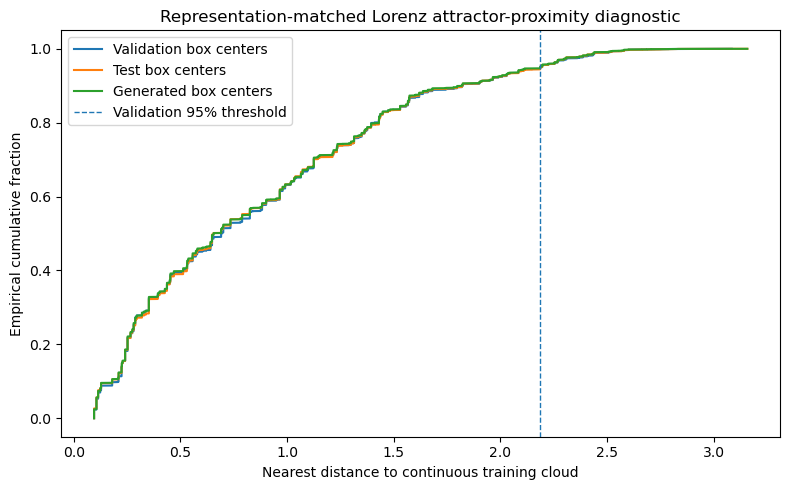

Saved: result images\hw5_2\step8_attractor_proximity_ecdf.png


In [6]:
training_cloud = np.vstack(
    train_continuous
)

tree = cKDTree(
    training_cloud
)

# Primary comparison: every evaluated sequence is represented by token box centers.
validation_center_cloud = np.vstack(
    validation_center_books
)

test_center_cloud = np.vstack(
    test_center_books
)

generated_cloud = np.vstack(
    generated_center_books
)

validation_center_distances = tree.query(
    validation_center_cloud,
    k=1,
)[0]

test_center_distances = tree.query(
    test_center_cloud,
    k=1,
)[0]

generated_distances = tree.query(
    generated_cloud,
    k=1,
)[0]

distance_threshold = float(
    np.quantile(
        validation_center_distances,
        0.95,
    )
)

# Continuous held-out states are retained only as a sensitivity diagnostic.
validation_continuous_cloud = np.vstack(
    validation_continuous
)

test_continuous_cloud = np.vstack(
    test_continuous
)

validation_continuous_distances = tree.query(
    validation_continuous_cloud,
    k=1,
)[0]

test_continuous_distances = tree.query(
    test_continuous_cloud,
    k=1,
)[0]


def distance_row(dataset, representation, distances, primary):
    return {
        "dataset": dataset,
        "representation": representation,
        "primary_matched_comparison": bool(primary),
        "count": len(distances),
        "mean_distance": float(distances.mean()),
        "median_distance": float(np.median(distances)),
        "p95_distance": float(np.quantile(distances, 0.95)),
        "fraction_within_validation_box_center_p95_threshold": float(
            np.mean(distances <= distance_threshold)
        ),
    }


proximity_summary = pd.DataFrame([
    distance_row(
        "validation",
        "continuous states (diagnostic only)",
        validation_continuous_distances,
        False,
    ),
    distance_row(
        "test",
        "continuous states (diagnostic only)",
        test_continuous_distances,
        False,
    ),
    distance_row(
        "validation",
        "token box centers",
        validation_center_distances,
        True,
    ),
    distance_row(
        "test",
        "token box centers",
        test_center_distances,
        True,
    ),
    distance_row(
        "generated",
        "token box centers",
        generated_distances,
        True,
    ),
])

proximity_path = (
    DATA_DIR
    / "task8_attractor_proximity.csv"
)

proximity_summary.to_csv(
    proximity_path,
    index=False,
)

print(
    "Validation box-center 95% distance threshold:",
    distance_threshold,
)
print()
print(proximity_summary.to_string(index=False))
print()
print("Saved:", proximity_path.relative_to(PROJECT_ROOT))

# ECDF plot for the representation-matched comparison.
plt.figure(figsize=(8, 5))

for label, distances in [
    ("Validation box centers", validation_center_distances),
    ("Test box centers", test_center_distances),
    ("Generated box centers", generated_distances),
]:
    xs = np.sort(distances)
    ys = np.arange(1, len(xs) + 1) / len(xs)
    plt.plot(xs, ys, label=label)

plt.axvline(
    distance_threshold,
    linestyle="--",
    linewidth=1,
    label="Validation 95% threshold",
)
plt.xlabel("Nearest distance to continuous training cloud")
plt.ylabel("Empirical cumulative fraction")
plt.title("Representation-matched Lorenz attractor-proximity diagnostic")
plt.legend()
plt.tight_layout()

path = (
    RESULT_DIR
    / "step8_attractor_proximity_ecdf.png"
)
plt.savefig(path, dpi=200, bbox_inches="tight")
plt.show()
print("Saved:", path.relative_to(PROJECT_ROOT))

## Visual comparison of true and generated trajectories

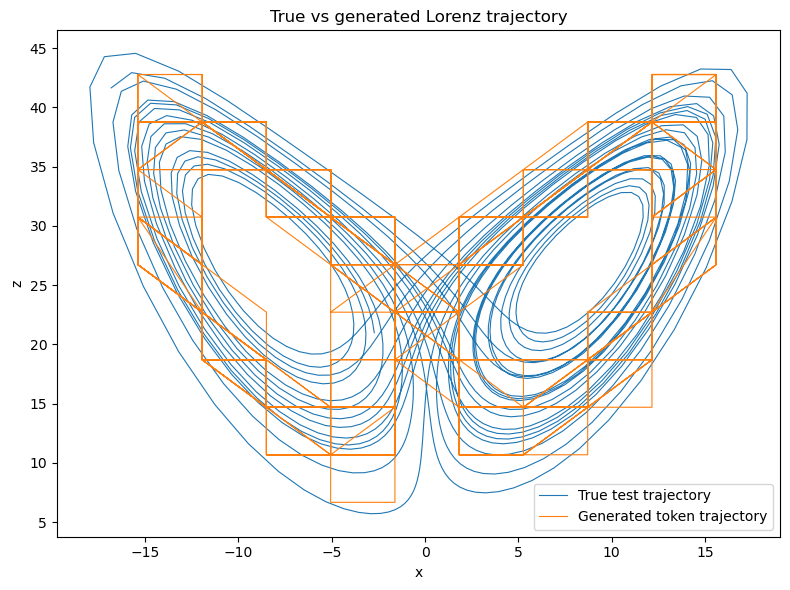

Saved: C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW5.2\result images\hw5_2\step8_true_vs_generated_xz.png


In [7]:
true_example = test_continuous[0]
generated_example = generated_center_books[0]

plt.figure(figsize=(8, 6))

plt.plot(
    true_example[:, 0],
    true_example[:, 2],
    linewidth=0.8,
    label="True test trajectory",
)

plt.plot(
    generated_example[:, 0],
    generated_example[:, 2],
    linewidth=0.8,
    label="Generated token trajectory",
)

plt.xlabel("x")
plt.ylabel("z")
plt.title("True vs generated Lorenz trajectory")
plt.legend()
plt.tight_layout()

path = (
    RESULT_DIR
    / "step8_true_vs_generated_xz.png"
)

plt.savefig(
    path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

print("Saved:", path.resolve())

## Two-lobe switching

The two main Lorenz lobes are identified by the reproducible diagnostic

$$
x<0
\qquad\text{versus}\qquad
x\ge 0.
$$

For each trajectory we compute:

- number of lobe switches;
- switch rate per 1000 sampled steps;
- mean residence time in one lobe;
- median residence time.

The primary comparison again uses the same representation on both sides: **true test token box centers** versus **generated token box centers**. The continuous true test trajectories are also reported as a sensitivity check. Quantization changes the average true-test switch rate only slightly, so the sign-of-$$x$$ diagnostic is stable at this resolution.

This comparison tests a specific long-time feature of Lorenz motion. Matching it does not prove equality of the full invariant distribution or establish that the generated sequence is a continuous ODE solution.

In [8]:
def lobe_residence_lengths(x_values):
    labels = np.where(
        x_values >= 0.0,
        1,
        -1,
    )

    change_indices = (
        np.flatnonzero(
            labels[1:]
            != labels[:-1]
        )
        + 1
    )

    boundaries = np.concatenate(
        [
            [0],
            change_indices,
            [len(labels)],
        ]
    )

    lengths = np.diff(
        boundaries
    )

    return labels, lengths


def switching_metrics(
    coordinate_books,
    label,
    representation,
):
    rows = []

    for book_index, states in enumerate(
        coordinate_books
    ):
        labels, residence_lengths = (
            lobe_residence_lengths(
                states[:, 0]
            )
        )

        switches = max(
            0,
            len(residence_lengths) - 1,
        )

        rows.append({
            "dataset": label,
            "representation": representation,
            "book": book_index,
            "samples": len(states),
            "switches": switches,
            "switches_per_1000_steps": (
                1000.0
                * switches
                / max(1, len(states) - 1)
            ),
            "mean_residence_steps": float(
                residence_lengths.mean()
            ),
            "median_residence_steps": float(
                np.median(residence_lengths)
            ),
            "mean_residence_time": float(
                residence_lengths.mean() * DT
            ),
        })

    return pd.DataFrame(rows)


true_continuous_switching = switching_metrics(
    test_continuous,
    "true_test_continuous",
    "continuous states",
)

true_center_switching = switching_metrics(
    test_center_books,
    "true_test_box_centers",
    "token box centers",
)

generated_switching = switching_metrics(
    generated_center_books,
    "generated_box_centers",
    "token box centers",
)

switching_table = pd.concat(
    [
        true_continuous_switching,
        true_center_switching,
        generated_switching,
    ],
    ignore_index=True,
)

switching_path = (
    DATA_DIR
    / "task8_lobe_switching_by_trajectory.csv"
)

switching_table.to_csv(
    switching_path,
    index=False,
)

summary = (
    switching_table
    .groupby("dataset")
    [
        [
            "switches_per_1000_steps",
            "mean_residence_steps",
            "mean_residence_time",
        ]
    ]
    .agg(["mean", "median", "std"])
)

print(summary)
print()
print("Saved:", switching_path.relative_to(PROJECT_ROOT))

matched_true_rate = float(
    true_center_switching["switches_per_1000_steps"].mean()
)
generated_rate = float(
    generated_switching["switches_per_1000_steps"].mean()
)

matched_true_residence = float(
    true_center_switching["mean_residence_time"].mean()
)
generated_residence = float(
    generated_switching["mean_residence_time"].mean()
)

print()
print("Primary representation-matched comparison")
print("True box-center switch rate:", matched_true_rate)
print("Generated switch rate:", generated_rate)
print("True box-center mean residence time:", matched_true_residence)
print("Generated mean residence time:", generated_residence)

                      switches_per_1000_steps                   \
                                         mean median       std   
dataset                                                          
generated_box_centers                  11.768   11.2  2.471121   
true_test_box_centers                  11.520   11.2  2.172965   
true_test_continuous                   11.360   11.2  2.058694   

                      mean_residence_steps                    \
                                      mean median        std   
dataset                                                        
generated_box_centers            82.653115   83.4  15.888244   
true_test_box_centers            83.676089   83.4  15.669025   
true_test_continuous             84.544839   83.4  15.023245   

                      mean_residence_time                   
                                     mean median       std  
dataset                                                     
generated_box_centers            1.

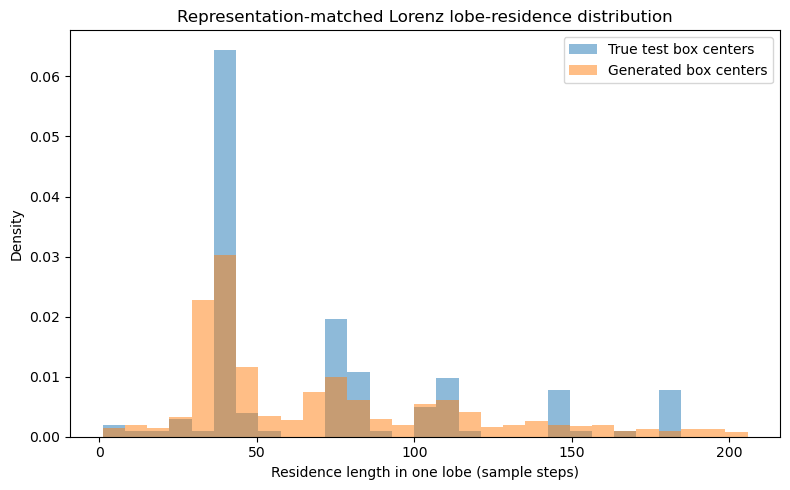

Saved: result images\hw5_2\step8_lobe_residence_distribution.png


In [9]:
def collect_residence_lengths(
    coordinate_books
):
    all_lengths = []

    for states in coordinate_books:
        _, lengths = (
            lobe_residence_lengths(
                states[:, 0]
            )
        )

        all_lengths.extend(
            lengths.tolist()
        )

    return np.asarray(
        all_lengths,
        dtype=float,
    )


true_residence = collect_residence_lengths(
    test_center_books
)

generated_residence = collect_residence_lengths(
    generated_center_books
)

upper = float(
    np.quantile(
        np.concatenate(
            [
                true_residence,
                generated_residence,
            ]
        ),
        0.95,
    )
)

bins = np.linspace(
    1,
    max(2.0, upper),
    30,
)

plt.figure(figsize=(8, 5))

plt.hist(
    true_residence,
    bins=bins,
    density=True,
    alpha=0.5,
    label="True test box centers",
)

plt.hist(
    generated_residence,
    bins=bins,
    density=True,
    alpha=0.5,
    label="Generated box centers",
)

plt.xlabel("Residence length in one lobe (sample steps)")
plt.ylabel("Density")
plt.title("Representation-matched Lorenz lobe-residence distribution")
plt.legend()
plt.tight_layout()

path = (
    RESULT_DIR
    / "step8_lobe_residence_distribution.png"
)

plt.savefig(
    path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

print("Saved:", path.relative_to(PROJECT_ROOT))

## Step 8 measured conclusion

With the representation mismatch removed, the generated states do **not** show the large attractor-proximity failure suggested by the earlier calculation.

Using the validation box-center 95% threshold:

- validation box centers: about **95.03%** lie within the threshold;
- held-out test box centers: about **95.03%** lie within the threshold;
- generated box centers: about **95.21%** lie within the threshold.

Their mean nearest-neighbor distances to the continuous training cloud are also very similar (approximately 0.857, 0.854, and 0.848 respectively).

However, this support-proximity result is **not an independent proof of dynamical fidelity**. The empirical Markov generator samples next tokens only from transitions observed in the training books, so generated states are restricted to training-observed token values. Remaining inside the coarse tokenized attractor support is therefore partly a structural consequence of the model. The more informative test is whether the generated **sequence dynamics** reproduce features such as lobe switching and residence times.

For that lobe diagnostic, the mean switch rate is approximately

$$
11.52\ \text{switches per 1000 steps}
$$

for true test box-center trajectories and

$$
11.77\ \text{switches per 1000 steps}
$$

for generated trajectories. Their mean residence times are also close (about 1.67 versus 1.65 time units).

Therefore the generated token sequences reproduce the tested coarse lobe-switching behavior reasonably well. This should not be overstated: the experiment does not establish equality of invariant measures, positive Lyapunov exponents, exact ODE fidelity, or full long-horizon chaotic statistics.

# Task 9 is not applicable to the selected Lorenz system

Task 9 asks for invariant checks for a Hamiltonian or nearly Hamiltonian system.

The selected Lorenz system is dissipative:

$$
\nabla\cdot F
=
-\frac{41}{3}<0.
$$

It is not the Hamiltonian/Kirchhoff option.

Therefore this project does **not** invent an energy, momentum, or Casimir conservation test for the Lorenz system. The physically relevant checks here are attractor proximity and two-lobe switching.

## Steps 7-8 outputs

### Data

- `task7_generated_sequence_manifest.csv`
- `generated_sequences/`
- `task8_attractor_proximity.csv`
- `task8_lobe_switching_by_trajectory.csv`

### Result images

- `step8_true_vs_generated_xz.png`
- `step8_attractor_proximity_ecdf.png`
- `step8_lobe_residence_distribution.png`

The next notebook varies only the discretization while holding the validation-selected Markov context length fixed.